<a href="https://colab.research.google.com/github/sshema-cpu/brain-tumor-mri-classification/blob/main/Ethan_Paredez_%26_Sam_Shema_Brain_Tumor_MRI_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor MRI Classification Using Deep Learning

### What are we trying to do?

For this project, we want to explore how deep learning can help distinguish between three types of brain tumors using MRI images: **meningioma, glioma, and pituitary tumors**.

We chose this topic because we are interested in healthcare and how technology can potentially support medical professionals in making better-informed decisions. We are also curious about how neural networks learn patterns from images, especially since we have been learning about how these networks are inspired by the human brain.

Our main goal is to compare two models: a **Convolutional Neural Network (CNN) built from scratch** and a **pretrained ResNet-18 model**.

Since our dataset is relatively small, we also want to investigate how different data augmentation techniques affect model performance.

### Our main research questions

1. How well can a CNN trained from scratch classify different types of brain tumors from MRI images compared with a pretrained ResNet-18?
2. How do different data augmentation techniques affect the performance of these models?
3. How does splitting the data by patient rather than by individual MRI image affect the reliability of our evaluation?

We hope to better understand not only how these models perform, but also **why certain approaches work better than others**.

*Note: Just so you know, this project is for educational and research purposes. Our models are not intended for clinical diagnosis.*

Done by Ethan Paredez and Sam Shema (TCU Students)


## Step 1: Now, We Are Starting by Setinng Up Our Deep Learning Environment

Before we start working with the MRI images, we first need to make sure our environment is ready.

We will use **PyTorch** to build and train our neural networks, and **Google Colab** to run our code.

Since training a CNN involves a lot of mathematical calculations, we want to take advantage of a GPU instead of relying only on a CPU. So, as to do parallel calculations all at once.

In the code below, we will:

- Import PyTorch and Torchvision.
- Check which versions we are using.
- Confirm whether a GPU is available.
- Select the device that our models will use during training.

This will help us make sure everything is working before we begin. And overall make our job easy.


In [1]:
import torch
import torchvision

In [2]:
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
GPU available: True


In [3]:
# if cuda exists, tn we will prefer to use it
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Selected device:", device)

Selected device: cuda


In [4]:
from pathlib import Path # folders and file path
import requests          # to communicate with websites and APIs

In [5]:
# Now, let's create a directory for our dataset
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

# The Figshare dataset article API
api_url = "https://api.figshare.com/v2/articles/1512427"

response = requests.get(api_url, timeout=30)
response.raise_for_status()

dataset_info = response.json()

# The files available for download are:
for file in dataset_info["files"]:
    print(file["name"], "-", round(file["size"] / 1024**2, 2), "MiB")

brainTumorDataPublic_1-766.zip - 204.47 MiB
brainTumorDataPublic_1533-2298.zip - 205.58 MiB
brainTumorDataPublic_767-1532.zip - 207.76 MiB
brainTumorDataPublic_2299-3064.zip - 220.95 MiB
cvind.mat - 0.01 MiB
README 2024.txt - 0.0 MiB


## Step 2: We Need to Access Our Brain Tumor MRI Dataset

Now that our environment is ready, the next step is to access the MRI images we will use to train and evaluate our models.

We are using the **Figshare Brain Tumor Dataset**, which contains 3,064 MRI images from 233 patients. The images represent three tumor types: meningioma, glioma, and pituitary tumors.

We download the dataset directly from Figshare into Colab’s temporary storage using the Figshare API. This avoids depending on a shared Google Drive folder and lets anyone rerun the notebook from scratch.

**Dataset source:** https://figshare.com/articles/dataset/brain_tumor_dataset/1512427


In [6]:
# Download the dataset straight from Figshare into Colab (no Google Drive needed)
from pathlib import Path
import requests

data_dir = Path("/content/1512427")
data_dir.mkdir(parents=True, exist_ok=True)

for file in dataset_info["files"]:
    target = data_dir / file["name"]
    if target.exists() and target.stat().st_size == file["size"]:
        print("Already downloaded:", file["name"])
        continue
    print("Downloading:", file["name"])
    with requests.get(file["download_url"], stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(target, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                f.write(chunk)

print("Done! Files:", sorted(p.name for p in data_dir.iterdir()))

Downloading: brainTumorDataPublic_1-766.zip
Downloading: brainTumorDataPublic_1533-2298.zip
Downloading: brainTumorDataPublic_767-1532.zip
Downloading: brainTumorDataPublic_2299-3064.zip
Downloading: cvind.mat
Downloading: README 2024.txt
Done! Files: ['README 2024.txt', 'brainTumorDataPublic_1-766.zip', 'brainTumorDataPublic_1533-2298.zip', 'brainTumorDataPublic_2299-3064.zip', 'brainTumorDataPublic_767-1532.zip', 'cvind.mat']


In [7]:


from pathlib import Path

# Location of our downloaded MRI dataset
# data_dir = Path("/content/drive/MyDrive/1512427")

# Check whether the folder exists
print("Folder exists:", data_dir.exists())

# Display all files inside the folder
if data_dir.exists():
    for file in sorted(data_dir.iterdir()):
        print(file.name)
else:
    print("Folder not found. Check Google Drive connection.")



Folder exists: True
README 2024.txt
brainTumorDataPublic_1-766.zip
brainTumorDataPublic_1533-2298.zip
brainTumorDataPublic_2299-3064.zip
brainTumorDataPublic_767-1532.zip
cvind.mat


##Step 3: Extracting Our MRI Images

Our MRI dataset is currently stored in four ZIP files. Each ZIP file contains a portion of the MRI images.

Before we can work with these images, we need to extract the files so that Python can access them individually.

We will extract them into Google Colab's temporary storage into Google Colab’s temporary storage. This should make it faster to read and process the images when we start training our models.

We are expecting 3,064 MRI files.

In [8]:

import zipfile
from pathlib import Path

# Folder for extracted MRI files in Colab
extract_dir = Path("/content/brain_tumor_data")
extract_dir.mkdir(parents=True, exist_ok=True)

# Find the four ZIP archives we downloaded
zip_files = sorted(data_dir.glob("*.zip"))

print("ZIP files found:", len(zip_files))

# Extract each archive
for zip_path in zip_files:
    print("Extracting:", zip_path.name)

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

    print("Finished:", zip_path.name)

print("Extraction complete!")


ZIP files found: 4
Extracting: brainTumorDataPublic_1-766.zip
Finished: brainTumorDataPublic_1-766.zip
Extracting: brainTumorDataPublic_1533-2298.zip
Finished: brainTumorDataPublic_1533-2298.zip
Extracting: brainTumorDataPublic_2299-3064.zip
Finished: brainTumorDataPublic_2299-3064.zip
Extracting: brainTumorDataPublic_767-1532.zip
Finished: brainTumorDataPublic_767-1532.zip
Extraction complete!


In [9]:

# Find all MATLAB files in the extracted directory
mat_files = sorted(extract_dir.rglob("*.mat"))

print("Number of MRI .mat files:", len(mat_files))

# Display the first five filenames
for file in mat_files[:5]:
    print(file)


Number of MRI .mat files: 3064
/content/brain_tumor_data/1.mat
/content/brain_tumor_data/10.mat
/content/brain_tumor_data/100.mat
/content/brain_tumor_data/1000.mat
/content/brain_tumor_data/1001.mat


##Step 4: Getting to Know Our MRI Images

Now that we've successfully extracted all 3,064 MRI files, let's take a look at what we're actually working with!

Before teaching our models to recognize different tumors, we first want to understand what these images look like, how they're labeled, and how they're organized.

We'll start by opening one MRI file and exploring what's inside.

In [10]:

import h5py    # to read HDF5 files

# Select our first MRI file
sample_file = mat_files[0]

# Open the file and see what's inside
with h5py.File(sample_file, "r") as f:
    print("File:", sample_file.name)
    print("Contents:", list(f.keys()))



File: 1.mat
Contents: ['cjdata']


In [11]:

with h5py.File(sample_file, "r") as f:

    for key in f.keys():
        item = f[key]

        print("Name:", key)
        print("Type:", type(item))

        if isinstance(item, h5py.Dataset):
            print("Shape:", item.shape)

        elif isinstance(item, h5py.Group):
            print("Contains:", list(item.keys()))

        print()


Name: cjdata
Type: <class 'h5py._hl.group.Group'>
Contains: ['PID', 'image', 'label', 'tumorBorder', 'tumorMask']



## Step 5: Seeing Our First MRI Image!

We've finally figured out how our MRI files are organized! Each file contains an image, its tumor label, and information about the patient.

Now, let's actually display one of these images and see which tumor category it belongs to.

This will help us connect the numbers in our dataset to the images our CNN will eventually learn from.


In [12]:

import h5py
import numpy as np

with h5py.File(sample_file, "r") as f:
    data = f["cjdata"]

    # Load the MRI image
    image = np.array(data["image"])

    # Load the tumor label
    label = int(np.array(data["label"]).item())

    # Load the patient identifier
    pid_codes = np.array(data["PID"]).flatten()
    patient_id = "".join(chr(int(x)) for x in pid_codes)

print("Image shape:", image.shape)
print("Tumor label:", label)
print("Patient ID:", patient_id)


Image shape: (512, 512)
Tumor label: 1
Patient ID: 100360


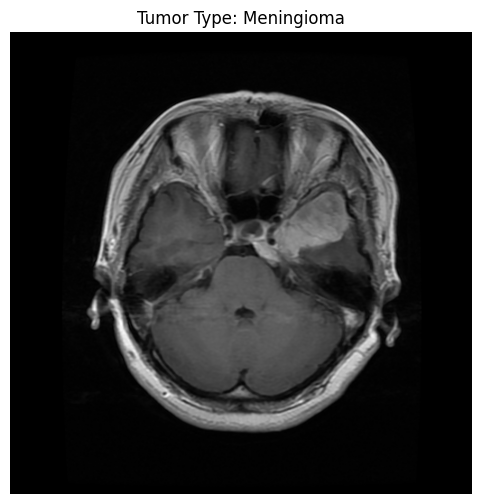

In [13]:

import matplotlib.pyplot as plt

# Convert the image to the usual viewing orientation
display_image = image.T

# Match the numerical label to its tumor name
tumor_types = {
    1: "Meningioma",
    2: "Glioma",
    3: "Pituitary Tumor"
}

plt.figure(figsize=(6, 6))

plt.imshow(display_image, cmap="gray")

plt.title(
    f"Tumor Type: {tumor_types[label]}"
)

plt.axis("off")
plt.show()


##Step 6: Understanding Our Dataset Better

We've seen our first MRI image, and it's a meningioma! But that's just one image out of 3,064.

Now, we are curious about how many images we have for each tumor type and how many different patients they come from.

Let's explore that before we start teaching our models anything.

In [14]:

from collections import Counter

tumor_counts = Counter()
patient_ids = set()

for file in mat_files:
    with h5py.File(file, "r") as f:
        data = f["cjdata"]

        label = int(np.array(data["label"]).item())

        pid_codes = np.array(data["PID"]).flatten()
        patient_id = "".join(chr(int(x)) for x in pid_codes)

        tumor_counts[label] += 1
        patient_ids.add(patient_id)

for label, count in sorted(tumor_counts.items()):
    print(f"{tumor_types[label]}: {count} images")

print("Total images:", sum(tumor_counts.values()))
print("Unique patients:", len(patient_ids))


Meningioma: 708 images
Glioma: 1426 images
Pituitary Tumor: 930 images
Total images: 3064
Unique patients: 233


##Step 7: Splitting Data for Our Test

Here's something we found interesting: we have 3,064 images, but only 233 patients! That means some patients have multiple images.

We don't want our model to recognize a patient it has already seen and mistake that for learning how to recognize tumors.

So, we'll make sure each patient belongs to only one group: training, validation, or testing.

In [15]:

# We'll store the important information about each MRI image here:
records = []

for file in mat_files:
    with h5py.File(file, "r") as f:
        data = f["cjdata"]

        label = int(np.array(data["label"]).item())

        pid_codes = np.array(data["PID"]).flatten()
        patient_id = "".join(chr(int(x)) for x in pid_codes)

        records.append({
            "file": str(file),
            "label": label,
            "patient_id": patient_id
        })

print("Images organized:", len(records))
print("Example record:", records[0])


Images organized: 3064
Example record: {'file': '/content/brain_tumor_data/1.mat', 'label': 1, 'patient_id': '100360'}


In [17]:
# Now, we will divide our data into three categories

from sklearn.model_selection import train_test_split
from collections import defaultdict

# Find each patient's tumor category
patient_labels = defaultdict(set)

for record in records:
    patient_labels[record["patient_id"]].add(record["label"])

# Make sure every patient belongs to only one tumor category
assert all(len(labels) == 1 for labels in patient_labels.values())

# Get all unique patients and their tumor categories
patients = sorted(patient_labels.keys())

patient_tumors = [
    next(iter(patient_labels[pid]))
    for pid in patients
]

# Split patients into training (70%) and remaining (30%)
train_patients, remaining_patients = train_test_split(
    patients,
    test_size=0.30,
    random_state=42,
    stratify=patient_tumors
)

# Get tumor categories for the remaining patients
remaining_tumors = [
    next(iter(patient_labels[pid]))
    for pid in remaining_patients
]

# Split the remaining patients into validation and testing
val_patients, test_patients = train_test_split(
    remaining_patients,
    test_size=0.50,
    random_state=42,
    stratify=remaining_tumors
)

# Convert patient lists into sets
train_ids = set(train_patients)
val_ids = set(val_patients)
test_ids = set(test_patients)

# Assign MRI images to their respective groups
train_records = [
    r for r in records if r["patient_id"] in train_ids
]

val_records = [
    r for r in records if r["patient_id"] in val_ids
]

test_records = [
    r for r in records if r["patient_id"] in test_ids
]

# Display the number of images and patients in each group
print("Training:", len(train_records), "images")
print("Validation:", len(val_records), "images")
print("Testing:", len(test_records), "images")

print("\nPatient counts:")
print("Training:", len(train_ids))
print("Validation:", len(val_ids))
print("Testing:", len(test_ids))

# Make sure every image is included
assert len(train_records) + len(val_records) + len(test_records) == len(records)

# Make sure no patient appears in multiple groups
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("\nSuccess! All images are assigned and no patients overlap.")

Training: 2150 images
Validation: 494 images
Testing: 420 images

Patient counts:
Training: 163
Validation: 35
Testing: 35

Success! All images are assigned and no patients overlap.


In [18]:
# Let's check whether all three groups have a good mix of the tumor categories before we move forward.
# Since changing the seed number changes the image number as well


from collections import Counter

# Put our three groups together for comparison
splits = {
    "Training": train_records,
    "Validation": val_records,
    "Testing": test_records
}

# Count each tumor type in every group
for split_name, split_records in splits.items():

    counts = Counter(r["label"] for r in split_records)

    print(f"\n{split_name} ({len(split_records)} images)")

    for label, tumor_name in tumor_types.items():
        count = counts[label]
        percentage = count / len(split_records) * 100

        print(f"{tumor_name}: {count} ({percentage:.1f}%)")



Training (2150 images)
Meningioma: 468 (21.8%)
Glioma: 1010 (47.0%)
Pituitary Tumor: 672 (31.3%)

Validation (494 images)
Meningioma: 128 (25.9%)
Glioma: 228 (46.2%)
Pituitary Tumor: 138 (27.9%)

Testing (420 images)
Meningioma: 112 (26.7%)
Glioma: 188 (44.8%)
Pituitary Tumor: 120 (28.6%)


In [19]:
# Let's see patient-level stratification
from collections import defaultdict, Counter

patient_labels = defaultdict(set)

for record in records:
    patient_labels[record["patient_id"]].add(record["label"])

category_counts = Counter(
    len(labels) for labels in patient_labels.values()
)

print("Tumor categories per patient:")

for num_categories, num_patients in sorted(category_counts.items()):
    print(f"{num_categories} category/categories: {num_patients} patients")

Tumor categories per patient:
1 category/categories: 233 patients


##Step 8: Checking if Dataset is Ready

We've explored our dataset and divided it into groups that should give our models a fair chance to learn and be tested.

We want to understand their sizes and pixel values. That way, we'll know what needs to be adjusted before feeding them into our neural networks.


In [20]:
import h5py
import numpy as np
from collections import Counter

# Keep track of the different image sizes
image_shapes = Counter()

# Find the smallest and largest pixel values
min_pixel = float("inf")
max_pixel = float("-inf")

# Examine every MRI image
for record in records:
    with h5py.File(record["file"], "r") as f:
        image = np.array(f["cjdata"]["image"])

        image_shapes[image.shape] += 1

        min_pixel = min(min_pixel, image.min())
        max_pixel = max(max_pixel, image.max())

print("Image dimensions:")
for shape, count in image_shapes.items():
    print(f"{shape}: {count} images")

print("\nMinimum pixel value:", min_pixel)
print("Maximum pixel value:", max_pixel)

Image dimensions:
(512, 512): 3049 images
(256, 256): 15 images

Minimum pixel value: 0
Maximum pixel value: 12728


## Step 9: Getting Our Images Into PyTorch

Our images aren't all the same size, and their pixel values vary quite a bit. So we'll prepare them in a consistent way before feeding them into a neural network.

We'll also set things up so we can experiment with different image transformations later, without changing our original data.

This creates a reusable dataset object. Whenever PyTorch requests an image, the class opens its .mat file, scales the image to approximately 0–1, applies our selected transformations, and returns the image with its label.

In [21]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import numpy as np
import h5py

class BrainTumorDataset(Dataset):

    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        record = self.records[index]

        # Read the MRI image
        with h5py.File(record["file"], "r") as f:
            image = np.array(f["cjdata"]["image"])

        # Convert to floating point and scale each image
        # Basically this is Normalization
        image = image.astype(np.float32)
        image = image - image.min()

        if image.max() > 0:
            image = image / image.max()

        # Convert to a grayscale PIL image
        image = Image.fromarray(image)

        # Apply resizing and other transformations
        if self.transform:
            image = self.transform(image)  # use different augmentation styles

        # PyTorch class labels start at 0
        label = record["label"] - 1

        return image, label

We use a batch size of 16...Our GPU access is still inactive

In [22]:
# Basic preprocessing without augmentation
basic_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Create the datasets
train_dataset = BrainTumorDataset(
    train_records, transform=basic_transform
)

val_dataset = BrainTumorDataset(
    val_records, transform=basic_transform
)

test_dataset = BrainTumorDataset(
    test_records, transform=basic_transform
)

# Create the data loaders
train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=16, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False, num_workers=2
)

# Test one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())

Image batch shape: torch.Size([16, 1, 224, 224])
Label batch shape: torch.Size([16])
Pixel range: 0.0 0.9634774923324585


## Step 10: Building Our First CNN!

We'll start with a relatively simple. We are intending for this to give us a starting point that we can later compare with ResNet-18 and different augmentation techniques.


In [23]:

import torch
import torch.nn as nn

class BrainTumorCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Learn visual patterns from MRI images using ReLU as activation fn
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        # Predict one of the three tumor categories
        self.classifier = nn.Linear(64, 3)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


# Create our model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BrainTumorCNN().to(device)

print(model)
print("\nUsing device:", device)


BrainTumorCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=3, bias=True)
)

Using device: cuda


## Step 11: Reproducibility and Shared Helpers

Fixed seeds, a loader builder, and the train / evaluate functions shared by every experiment, so all models are trained and scored the same way.

Far the most important part __ The Training part.

In [27]:
import copy
import random
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

SEED = 42
BATCH_SIZE = 16
CLASS_NAMES = [tumor_types[i] for i in (1, 2, 3)]   # index 0, 1, 2


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    # Gives each DataLoader worker a reproducible seed
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loaders(train_recs, val_recs, test_recs, train_tf, eval_tf,
                 batch_size=BATCH_SIZE):
    g = torch.Generator()
    g.manual_seed(SEED)
    train_dl = DataLoader(
        BrainTumorDataset(train_recs, transform=train_tf),
        batch_size=batch_size, shuffle=True, num_workers=2,
        worker_init_fn=seed_worker, generator=g,
    )
    val_dl = DataLoader(
        BrainTumorDataset(val_recs, transform=eval_tf),
        batch_size=batch_size, shuffle=False, num_workers=2,
    )
    test_dl = DataLoader(
        BrainTumorDataset(test_recs, transform=eval_tf),
        batch_size=batch_size, shuffle=False, num_workers=2,
    )
    return train_dl, val_dl, test_dl


def compute_metrics(labels, preds):
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro", zero_division=0),
        "per_class_recall": recall_score(
            labels, preds, average=None, labels=[0, 1, 2], zero_division=0
        ),
    }


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, all_preds, all_labels = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)            # CNN makes prediction here
                                           # Forward Propagation
        loss = criterion(outputs, labels)  # How wrong the model is
        loss.backward()                    # Back Propagation
        optimizer.step()                   # Adjusting the parameters here

        total_loss += loss.item() * images.size(0)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = compute_metrics(all_labels, all_preds)
    metrics["loss"] = total_loss / len(loader.dataset)
    return metrics




In [28]:
# Evaluation Here...

@torch.no_grad()
def evaluate(model, loader, criterion=None):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        if criterion is not None:
            total_loss += criterion(outputs, labels).item() * images.size(0)
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    metrics = compute_metrics(all_labels, all_preds)
    metrics["loss"] = total_loss / len(loader.dataset)
    metrics["preds"] = np.array(all_preds)
    metrics["labels"] = np.array(all_labels)
    return metrics


def class_weights_from(recs):
    # Inverse-frequency weights: total / (num_classes * count)
    counts = Counter(r["label"] - 1 for r in recs)
    total = sum(counts.values())
    w = [total / (3 * counts[c]) for c in range(3)]
    return torch.tensor(w, dtype=torch.float32, device=device)


def fit(model, train_dl, val_dl, epochs, lr, weight_decay=1e-4,
        class_weights=None, name="model"):
    """Train, keep the epoch with the best VALIDATION macro-F1, restore it."""
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr,
                                 weight_decay=weight_decay)

    history = {k: [] for k in
               ["train_loss", "val_loss", "train_acc", "val_acc", "val_f1"]}
    best_f1, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        start = time.time()
        tr = train_one_epoch(model, train_dl, criterion, optimizer)
        va = evaluate(model, val_dl, criterion)

        history["train_loss"].append(tr["loss"])
        history["val_loss"].append(va["loss"])
        history["train_acc"].append(tr["accuracy"])
        history["val_acc"].append(va["accuracy"])
        history["val_f1"].append(va["macro_f1"])

        if va["macro_f1"] > best_f1:
            best_f1, best_epoch = va["macro_f1"], epoch
            best_state = copy.deepcopy(model.state_dict())

        print(f"[{name}] epoch {epoch:2d}/{epochs} | "
              f"train loss {tr['loss']:.3f} acc {tr['accuracy']:.3f} | "
              f"val loss {va['loss']:.3f} acc {va['accuracy']:.3f} "
              f"F1 {va['macro_f1']:.3f} | {time.time() - start:.0f}s")

    model.load_state_dict(best_state)
    print(f"\n[{name}] best validation macro-F1 {best_f1:.3f} at epoch {best_epoch}")
    history["best_epoch"] = best_epoch
    return history


def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_title(f"{title}: loss")
    axes[0].set_xlabel("epoch")
    axes[0].legend()

    axes[1].plot(epochs, history["train_acc"], label="train accuracy")
    axes[1].plot(epochs, history["val_acc"], label="val accuracy")
    axes[1].plot(epochs, history["val_f1"], label="val macro-F1")
    axes[1].axvline(history["best_epoch"], color="gray", linestyle="--",
                    label="best epoch")
    axes[1].set_title(f"{title}: accuracy / F1")
    axes[1].set_xlabel("epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


# All final TEST results are collected here for the summary table
results = {}


def report_test(model, test_dl, name, split_name):
    te = evaluate(model, test_dl)
    results[name] = {
        "split": split_name,
        "test_accuracy": te["accuracy"],
        "test_macro_f1": te["macro_f1"],
        **{f"recall_{c}": r for c, r in zip(CLASS_NAMES, te["per_class_recall"])},
    }

    print(f"=== {name} | {split_name} split | TEST set ===")
    print(classification_report(te["labels"], te["preds"], labels=[0, 1, 2],
                                target_names=CLASS_NAMES, digits=3,
                                zero_division=0))

    cm = confusion_matrix(te["labels"], te["preds"], labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        cmap="Blues", values_format="d")
    plt.title(f"{name} - test confusion matrix ({split_name} split)")
    plt.show()
    return te

## Step 12: Majority-Class Baseline

We want to always predict the most common tumor type in the training set. Any useful model has to clearly beat this.

In [29]:
train_label_ids = [r["label"] - 1 for r in train_records]
majority_class = Counter(train_label_ids).most_common(1)[0][0]

test_label_ids = np.array([r["label"] - 1 for r in test_records])
majority_preds = np.full_like(test_label_ids, majority_class)

m = compute_metrics(test_label_ids, majority_preds)
results["Majority class"] = {
    "split": "patient-level",
    "test_accuracy": m["accuracy"],
    "test_macro_f1": m["macro_f1"],
    **{f"recall_{c}": r for c, r in zip(CLASS_NAMES, m["per_class_recall"])},
}

print("Majority class:", CLASS_NAMES[majority_class])
print(f"Test accuracy: {m['accuracy']:.3f}")
print(f"Test macro-F1: {m['macro_f1']:.3f}")

Majority class: Glioma
Test accuracy: 0.448
Test macro-F1: 0.206


## Step 13: Experiment 1 - CNN From Scratch (Patient-Level Split)

Train the Step 10 CNN on the patient-level split. The epoch with the best validation macro-F1 is kept, and only that model is scored on the test set.

We are planning to train on 25 epochs with 0.001 learning rate

[CNN] epoch  1/25 | train loss 1.000 acc 0.538 | val loss 0.924 acc 0.601 F1 0.460 | 17s
[CNN] epoch  2/25 | train loss 0.808 acc 0.644 | val loss 0.897 acc 0.569 F1 0.435 | 14s
[CNN] epoch  3/25 | train loss 0.774 acc 0.656 | val loss 0.824 acc 0.593 F1 0.452 | 14s
[CNN] epoch  4/25 | train loss 0.764 acc 0.654 | val loss 0.843 acc 0.579 F1 0.496 | 14s
[CNN] epoch  5/25 | train loss 0.757 acc 0.656 | val loss 0.892 acc 0.579 F1 0.493 | 14s
[CNN] epoch  6/25 | train loss 0.742 acc 0.667 | val loss 0.769 acc 0.601 F1 0.510 | 17s
[CNN] epoch  7/25 | train loss 0.736 acc 0.664 | val loss 0.748 acc 0.619 F1 0.557 | 14s
[CNN] epoch  8/25 | train loss 0.729 acc 0.679 | val loss 0.870 acc 0.589 F1 0.450 | 14s
[CNN] epoch  9/25 | train loss 0.731 acc 0.681 | val loss 0.780 acc 0.605 F1 0.509 | 14s
[CNN] epoch 10/25 | train loss 0.720 acc 0.688 | val loss 0.787 acc 0.595 F1 0.470 | 14s
[CNN] epoch 11/25 | train loss 0.723 acc 0.683 | val loss 0.797 acc 0.619 F1 0.581 | 14s
[CNN] epoch 12/25 | t

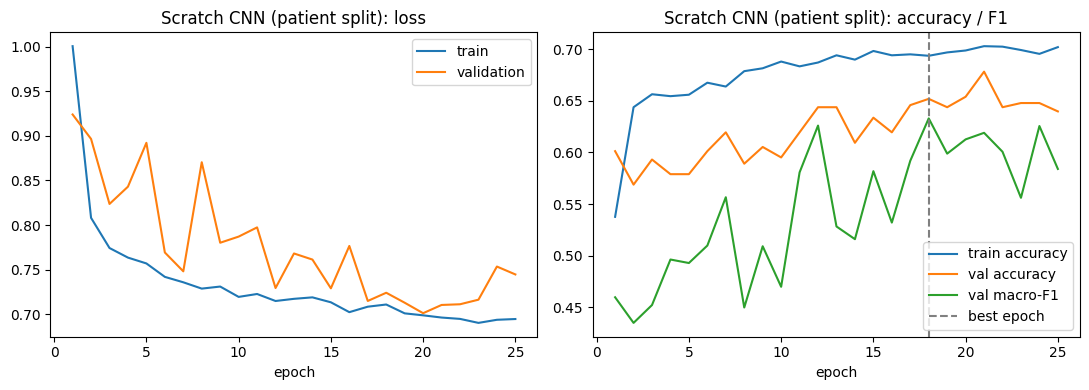

In [30]:
CNN_EPOCHS = 25
CNN_LR = 1e-3

set_seed()
cnn_train_dl, cnn_val_dl, cnn_test_dl = make_loaders(
    train_records, val_records, test_records,
    train_tf=basic_transform, eval_tf=basic_transform,
)

cnn_model = BrainTumorCNN().to(device)
cnn_history = fit(cnn_model, cnn_train_dl, cnn_val_dl,
                  epochs=CNN_EPOCHS, lr=CNN_LR, name="CNN")
plot_history(cnn_history, "Scratch CNN (patient split)")

=== Scratch CNN | patient-level split | TEST set ===
                 precision    recall  f1-score   support

     Meningioma      0.673     0.607     0.638       112
         Glioma      0.747     0.723     0.735       188
Pituitary Tumor      0.686     0.783     0.732       120

       accuracy                          0.710       420
      macro avg      0.702     0.705     0.702       420
   weighted avg      0.710     0.710     0.708       420



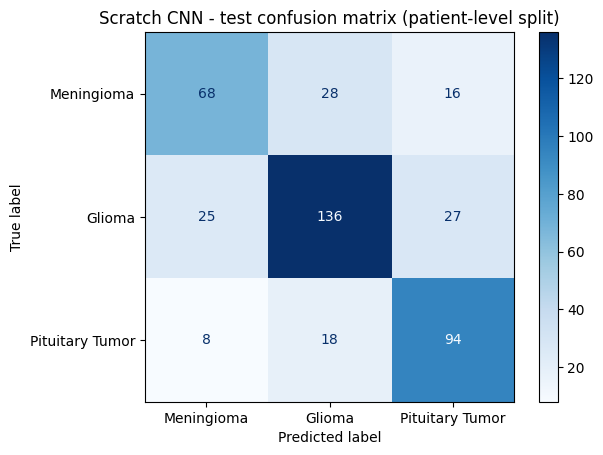

In [31]:
cnn_test = report_test(cnn_model, cnn_test_dl,
                       name="Scratch CNN", split_name="patient-level")

## Step 14: Experiment 2 - Pretrained ResNet-18 (Patient-Level Split)

Same split, same resizing, same selection rule. The only input difference: ResNet-18 was pretrained on 3-channel ImageNet images, so the grayscale MRI is copied into 3 channels and normalized with the ImageNet mean and std that the pretrained weights expect.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]


[ResNet-18] epoch  1/10 | train loss 0.261 acc 0.900 | val loss 0.206 acc 0.931 F1 0.929 | 20s
[ResNet-18] epoch  2/10 | train loss 0.048 acc 0.989 | val loss 0.156 acc 0.947 F1 0.948 | 21s
[ResNet-18] epoch  3/10 | train loss 0.041 acc 0.986 | val loss 0.224 acc 0.939 F1 0.939 | 19s
[ResNet-18] epoch  4/10 | train loss 0.022 acc 0.995 | val loss 0.179 acc 0.947 F1 0.945 | 19s
[ResNet-18] epoch  5/10 | train loss 0.007 acc 0.999 | val loss 0.229 acc 0.937 F1 0.937 | 19s
[ResNet-18] epoch  6/10 | train loss 0.009 acc 0.998 | val loss 0.219 acc 0.935 F1 0.934 | 19s
[ResNet-18] epoch  7/10 | train loss 0.004 acc 1.000 | val loss 0.275 acc 0.939 F1 0.938 | 19s
[ResNet-18] epoch  8/10 | train loss 0.042 acc 0.986 | val loss 0.204 acc 0.917 F1 0.915 | 19s
[ResNet-18] epoch  9/10 | train loss 0.023 acc 0.992 | val loss 0.176 acc 0.937 F1 0.937 | 19s
[ResNet-18] epoch 10/10 | train loss 0.016 acc 0.993 | val loss 0.171 acc 0.951 F1 0.951 | 19s

[ResNet-18] best validation macro-F1 0.951 at epo

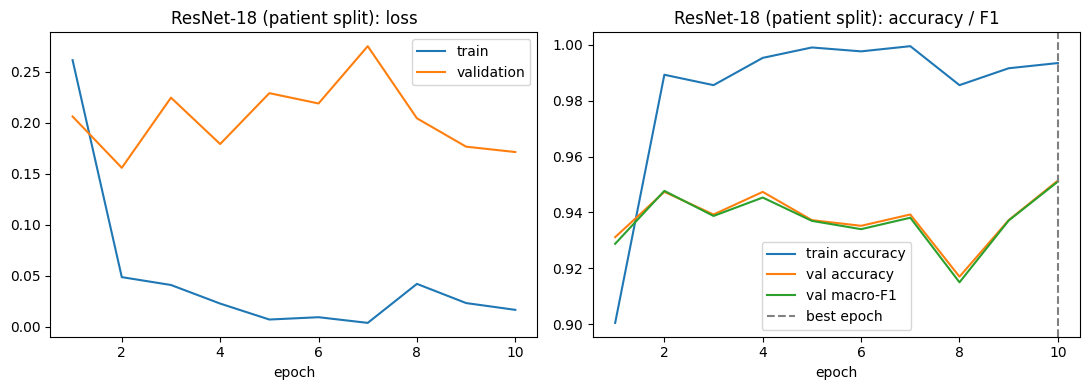

In [32]:
from torchvision.models import resnet18, ResNet18_Weights

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def to_three_channels(x):
    # Named function (not a lambda) so it works with num_workers > 0
    return x.repeat(3, 1, 1)


resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Lambda(to_three_channels),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def build_resnet18():
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, 3)   # 3 tumor classes
    return model


RESNET_EPOCHS = 10
RESNET_LR = 1e-4   # smaller LR so fine-tuning doesn't wreck pretrained weights

set_seed()
res_train_dl, res_val_dl, res_test_dl = make_loaders(
    train_records, val_records, test_records,
    train_tf=resnet_transform, eval_tf=resnet_transform,
)

resnet_model = build_resnet18().to(device)
resnet_history = fit(resnet_model, res_train_dl, res_val_dl,
                     epochs=RESNET_EPOCHS, lr=RESNET_LR, name="ResNet-18")
plot_history(resnet_history, "ResNet-18 (patient split)")

=== ResNet-18 | patient-level split | TEST set ===
                 precision    recall  f1-score   support

     Meningioma      0.828     0.857     0.842       112
         Glioma      0.908     0.947     0.927       188
Pituitary Tumor      0.944     0.850     0.895       120

       accuracy                          0.895       420
      macro avg      0.893     0.885     0.888       420
   weighted avg      0.897     0.895     0.895       420



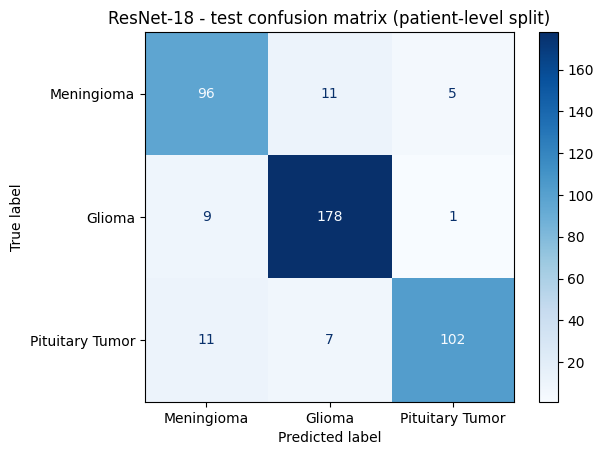

In [33]:
resnet_test = report_test(resnet_model, res_test_dl,
                          name="ResNet-18", split_name="patient-level")

## Step 15: Experiment 3 - Image-Level Split (Leakage Comparison)

Now split the same 3,064 images randomly by IMAGE (70/15/15, stratified by tumor type), ignoring which patient they came from. The same patient can then appear in both training and testing. We first measure how much overlap that creates, then train the scratch CNN with identical settings and compare.

In [35]:
all_labels = [r["label"] for r in records]
indices = np.arange(len(records))

img_train_idx, img_rem_idx = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=all_labels
)
img_val_idx, img_test_idx = train_test_split(
    img_rem_idx, test_size=0.50, random_state=SEED,
    stratify=[all_labels[i] for i in img_rem_idx]
)

img_train_records = [records[i] for i in img_train_idx]
img_val_records = [records[i] for i in img_val_idx]
img_test_records = [records[i] for i in img_test_idx]

img_train_patients = {r["patient_id"] for r in img_train_records}
img_test_patients = {r["patient_id"] for r in img_test_records}

leaked_images = sum(r["patient_id"] in img_train_patients
                    for r in img_test_records)
shared_patients = img_test_patients & img_train_patients

print("Image-level split:", len(img_train_records), "/",
      len(img_val_records), "/", len(img_test_records), "images")
print(f"Test patients also in training: {len(shared_patients)} "
      f"of {len(img_test_patients)}")
print(f"Test images whose patient is in training: {leaked_images} "
      f"of {len(img_test_records)} "
      f"({leaked_images / len(img_test_records):.1%})")

Image-level split: 2144 / 460 / 460 images
Test patients also in training: 180 of 184
Test images whose patient is in training: 455 of 460 (98.9%)


[CNN image-split] epoch  1/25 | train loss 1.003 acc 0.521 | val loss 0.843 acc 0.639 F1 0.479 | 18s
[CNN image-split] epoch  2/25 | train loss 0.826 acc 0.623 | val loss 0.785 acc 0.637 F1 0.476 | 14s
[CNN image-split] epoch  3/25 | train loss 0.795 acc 0.639 | val loss 0.773 acc 0.641 F1 0.480 | 14s
[CNN image-split] epoch  4/25 | train loss 0.777 acc 0.646 | val loss 0.745 acc 0.654 F1 0.554 | 14s
[CNN image-split] epoch  5/25 | train loss 0.759 acc 0.663 | val loss 0.760 acc 0.641 F1 0.497 | 14s
[CNN image-split] epoch  6/25 | train loss 0.754 acc 0.667 | val loss 0.748 acc 0.667 F1 0.565 | 14s
[CNN image-split] epoch  7/25 | train loss 0.735 acc 0.675 | val loss 0.748 acc 0.674 F1 0.638 | 14s
[CNN image-split] epoch  8/25 | train loss 0.738 acc 0.666 | val loss 0.724 acc 0.689 F1 0.646 | 14s
[CNN image-split] epoch  9/25 | train loss 0.737 acc 0.676 | val loss 0.724 acc 0.689 F1 0.638 | 14s
[CNN image-split] epoch 10/25 | train loss 0.738 acc 0.678 | val loss 0.720 acc 0.698 F1 0.

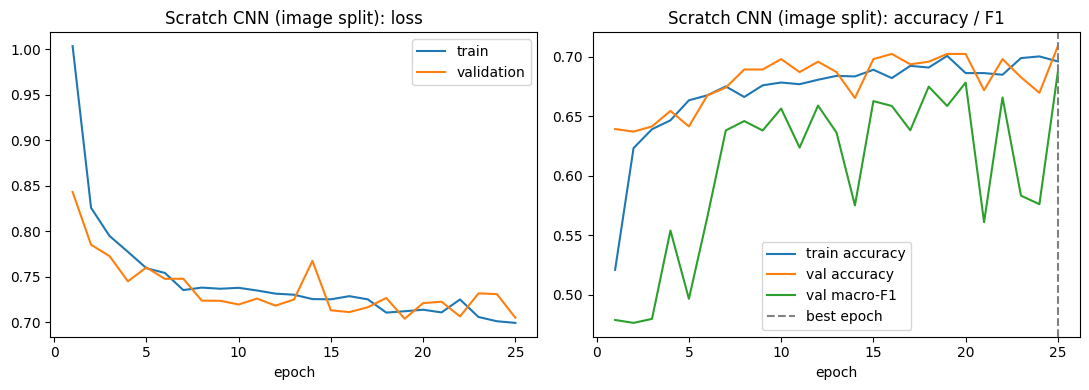

=== Scratch CNN (image split) | image-level split | TEST set ===
                 precision    recall  f1-score   support

     Meningioma      0.574     0.542     0.558       107
         Glioma      0.761     0.776     0.769       214
Pituitary Tumor      0.780     0.791     0.786       139

       accuracy                          0.726       460
      macro avg      0.705     0.703     0.704       460
   weighted avg      0.724     0.726     0.725       460



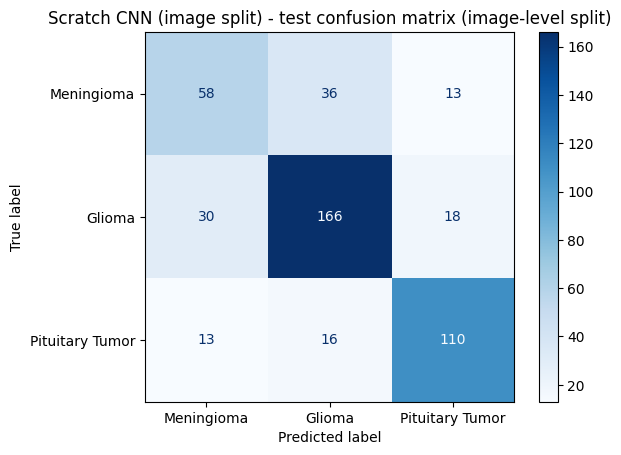

In [36]:
set_seed()
img_train_dl, img_val_dl, img_test_dl = make_loaders(
    img_train_records, img_val_records, img_test_records,
    train_tf=basic_transform, eval_tf=basic_transform,
)

cnn_img_model = BrainTumorCNN().to(device)
cnn_img_history = fit(cnn_img_model, img_train_dl, img_val_dl,
                      epochs=CNN_EPOCHS, lr=CNN_LR, name="CNN image-split")
plot_history(cnn_img_history, "Scratch CNN (image split)")

cnn_img_test = report_test(cnn_img_model, img_test_dl,
                           name="Scratch CNN (image split)",
                           split_name="image-level")

### Step 15b: ResNet-18 on the Image-Level Split

The scratch CNN barely changed with the leaky split, possibly because it is too small to memorize patients. ResNet-18 can memorize, so we repeat the leaky-split test with it.

[ResNet-18 image-split] epoch  1/10 | train loss 0.280 acc 0.888 | val loss 0.159 acc 0.943 F1 0.933 | 17s
[ResNet-18 image-split] epoch  2/10 | train loss 0.083 acc 0.972 | val loss 0.098 acc 0.967 F1 0.962 | 17s
[ResNet-18 image-split] epoch  3/10 | train loss 0.029 acc 0.992 | val loss 0.079 acc 0.967 F1 0.964 | 17s
[ResNet-18 image-split] epoch  4/10 | train loss 0.035 acc 0.990 | val loss 0.086 acc 0.967 F1 0.965 | 17s
[ResNet-18 image-split] epoch  5/10 | train loss 0.032 acc 0.990 | val loss 0.069 acc 0.983 F1 0.981 | 17s
[ResNet-18 image-split] epoch  6/10 | train loss 0.020 acc 0.995 | val loss 0.045 acc 0.985 F1 0.983 | 17s
[ResNet-18 image-split] epoch  7/10 | train loss 0.010 acc 0.998 | val loss 0.078 acc 0.974 F1 0.971 | 17s
[ResNet-18 image-split] epoch  8/10 | train loss 0.011 acc 0.997 | val loss 0.084 acc 0.980 F1 0.979 | 17s
[ResNet-18 image-split] epoch  9/10 | train loss 0.022 acc 0.993 | val loss 0.154 acc 0.957 F1 0.951 | 17s
[ResNet-18 image-split] epoch 10/10 |

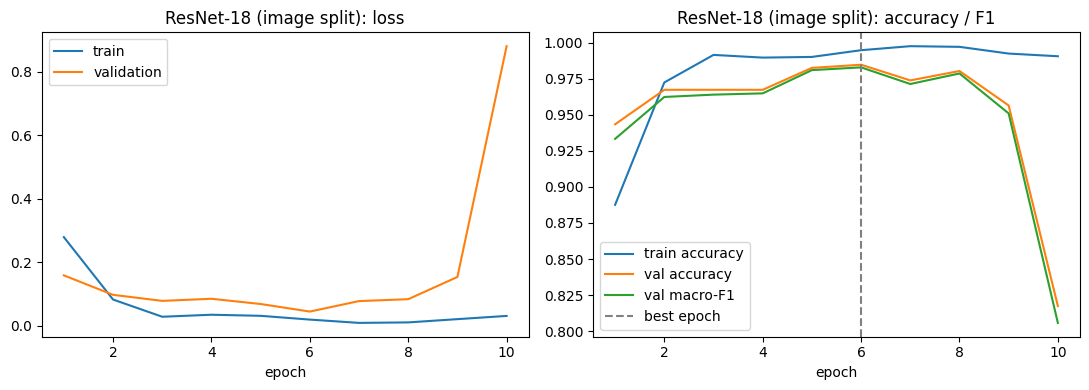

=== ResNet-18 (image split) | image-level split | TEST set ===
                 precision    recall  f1-score   support

     Meningioma      0.945     0.972     0.959       107
         Glioma      0.991     0.977     0.984       214
Pituitary Tumor      0.993     0.993     0.993       139

       accuracy                          0.980       460
      macro avg      0.976     0.980     0.978       460
   weighted avg      0.981     0.980     0.981       460



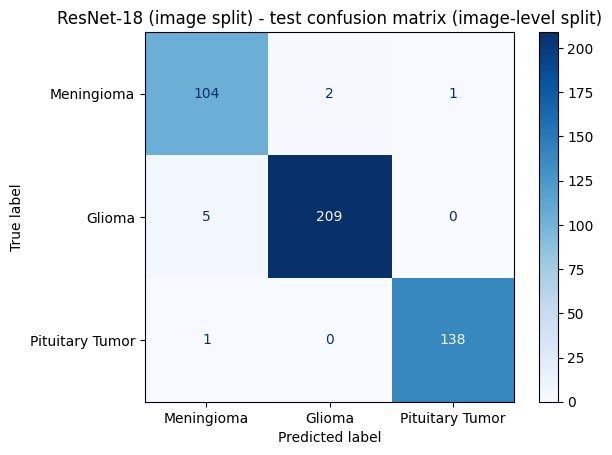

In [37]:
set_seed()
img_res_train_dl, img_res_val_dl, img_res_test_dl = make_loaders(
    img_train_records, img_val_records, img_test_records,
    train_tf=resnet_transform, eval_tf=resnet_transform,
)

resnet_img_model = build_resnet18().to(device)
resnet_img_history = fit(resnet_img_model, img_res_train_dl, img_res_val_dl,
                         epochs=RESNET_EPOCHS, lr=RESNET_LR,
                         name="ResNet-18 image-split")
plot_history(resnet_img_history, "ResNet-18 (image split)")

resnet_img_test = report_test(resnet_img_model, img_res_test_dl,
                              name="ResNet-18 (image split)",
                              split_name="image-level")

## Step 16: Results Summary

All numbers below are on each experiment's TEST set, using the model from the epoch with the best validation macro-F1.

In [38]:
summary = pd.DataFrame(results).T
num_cols = [c for c in summary.columns if c != "split"]
summary[num_cols] = summary[num_cols].astype(float).round(3)
summary

,split,test_accuracy,test_macro_f1,recall_Meningioma,recall_Glioma,recall_Pituitary Tumor
Majority class,patient-level,0.448,0.206,0.000,1.000,0.000
Scratch CNN,patient-level,0.710,0.702,0.607,0.723,0.783
ResNet-18,patient-level,0.895,0.888,0.857,0.947,0.850
Scratch CNN (image split),image-level,0.726,0.704,0.542,0.776,0.791
ResNet-18 (image split),image-level,0.980,0.978,0.972,0.977,0.993


## Step 17: Correct and Incorrect Predictions

A few test images from the patient-level split with the model's prediction, to look at what the model gets right and where it fails.

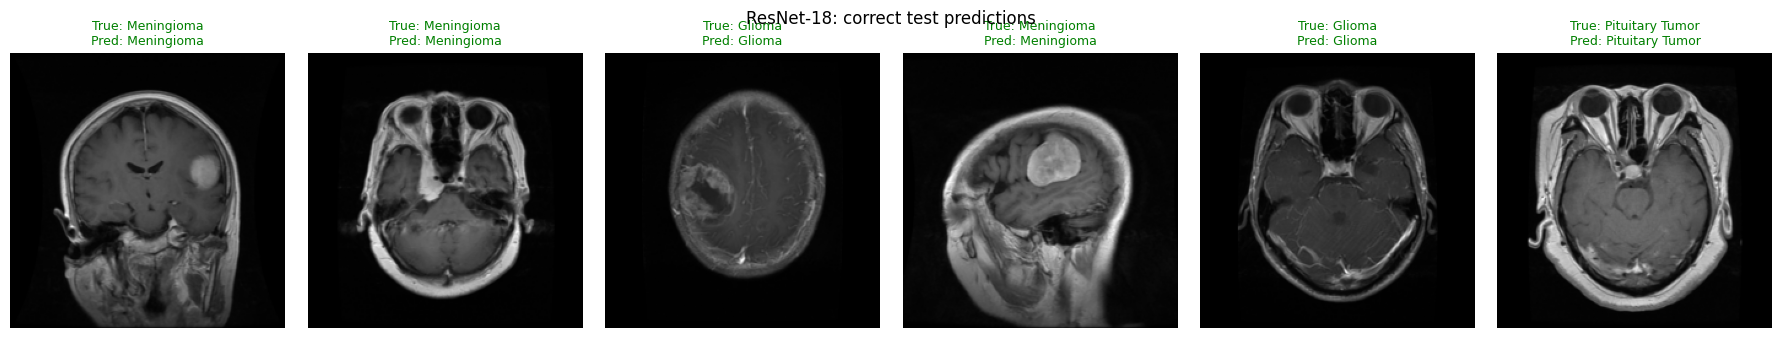

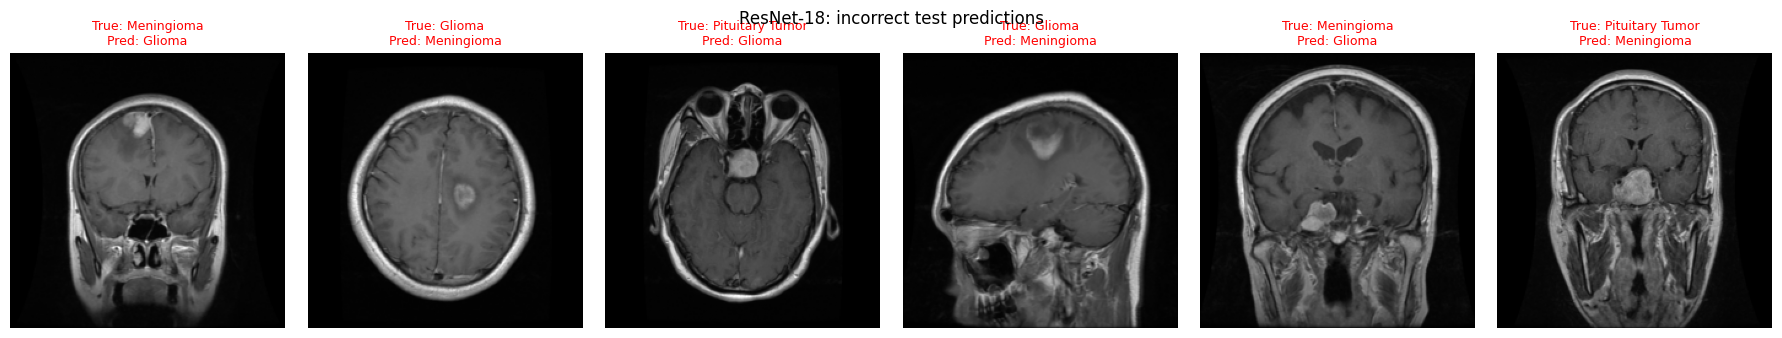

In [39]:
display_test_dataset = BrainTumorDataset(test_records, transform=basic_transform)


def show_examples(test_metrics, model_name, correct=True, n=6):
    preds, labels = test_metrics["preds"], test_metrics["labels"]
    mask = (preds == labels) if correct else (preds != labels)
    chosen = np.flatnonzero(mask)
    if len(chosen) == 0:
        print("No examples to show.")
        return
    rng = np.random.default_rng(SEED)
    chosen = rng.choice(chosen, size=min(n, len(chosen)), replace=False)

    fig, axes = plt.subplots(1, len(chosen), figsize=(3 * len(chosen), 3.4))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, chosen):
        image, _ = display_test_dataset[i]
        ax.imshow(image[0].numpy().T, cmap="gray")   # .T matches Step 5 orientation
        ax.set_title(f"True: {CLASS_NAMES[labels[i]]}\n"
                     f"Pred: {CLASS_NAMES[preds[i]]}",
                     fontsize=9, color="green" if correct else "red")
        ax.axis("off")
    kind = "correct" if correct else "incorrect"
    fig.suptitle(f"{model_name}: {kind} test predictions")
    plt.tight_layout()
    plt.show()


best_name, best_test = (("ResNet-18", resnet_test)
                        if resnet_test["macro_f1"] >= cnn_test["macro_f1"]
                        else ("Scratch CNN", cnn_test))

show_examples(best_test, best_name, correct=True)
show_examples(best_test, best_name, correct=False)